<a href="https://colab.research.google.com/github/lizagabriela80-afk/Data-analyse/blob/main/analyse0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Analyse des ventes et rétention (SQL & DuckDB)

**Objectif** : Comprendre la saisonnalité du chiffre d'affaires et calculer le taux de retour des clients (rétention) par cohorte.

**Données** : Olist (commandes, clients, items).

In [27]:
import os

# Définition de la variable d'environnement en syntaxe Python correcte
os.environ["KAGGLE_API_TOKEN"] = "KGAT_8e9b873480b3e32b8362abc113a0ee56"

In [28]:
import os
import zipfile

# Création du dossier de configuration Kaggle
kolab_kaggle_dir = os.path.expanduser('~/.kaggle')
os.makedirs(kolab_kaggle_dir, exist_ok=True)

# Enregistrement du token d'identification
with open(os.path.join(kolab_kaggle_dir, 'kaggle.json'), 'w') as f:
    f.write('{"username":"dummy","key":"' + os.environ.get("KAGGLE_API_TOKEN", "") + '"}')

# Attribution des permissions appropriées
os.chmod(os.path.join(kolab_kaggle_dir, 'kaggle.json'), 0o600)

try:
    print("Téléchargement du dataset d'Olist via l'API Kaggle...")
    os.system("kaggle datasets download -d olistbr/brazilian-ecommerce -p data --unzip")
    print("Téléchargement et extraction réussis !")
except Exception as e:
    print("Erreur lors du téléchargement :", e)

Téléchargement du dataset d'Olist via l'API Kaggle...
Téléchargement et extraction réussis !


In [29]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
# Connexion à DuckDB et création des vues sur les CSV
con = duckdb.connect()
con.execute("CREATE VIEW commandes AS SELECT * FROM read_csv_auto('data/olist_orders_dataset.csv')")
con.execute("CREATE VIEW clients AS SELECT * FROM read_csv_auto('data/olist_customers_dataset.csv')")
con.execute("CREATE VIEW items AS SELECT * FROM read_csv_auto('data/olist_order_items_dataset.csv')")

In [31]:
# Vérification
print("Tables chargées ! Nombre de commandes :", con.sql("SELECT COUNT(*) FROM commandes").fetchone()[0])

Tables chargées ! Nombre de commandes : 99441


**CA Mensuel et Saisonnalité**

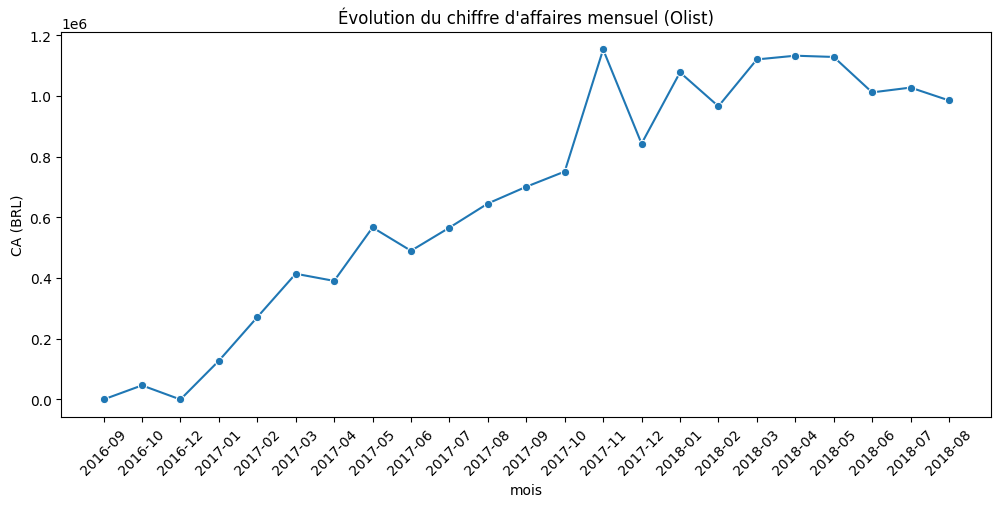

In [32]:
# Calcul du CA mensuel (uniquement commandes livrées)
requete_ca = """
SELECT
    strftime(o.order_purchase_timestamp, '%Y-%m') AS mois,
    COUNT(DISTINCT o.order_id) AS nb_commandes,
    ROUND(SUM(i.price + i.freight_value), 2) AS ca_total
FROM commandes o
JOIN items i ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY mois
ORDER BY mois
"""
df_ca = con.sql(requete_ca).df()

# Affichage graphique
plt.figure(figsize=(12, 5))
sns.lineplot(data=df_ca, x='mois', y='ca_total', marker='o')
plt.title("Évolution du chiffre d'affaires mensuel (Olist)")
plt.xticks(rotation=45)
plt.ylabel("CA (BRL)")
plt.show()

**Rétention par cohorte (Window Functions)**

In [33]:
# On identifie la 1ère commande de chaque client, puis on regarde le mois des commandes suivantes
requete_cohorte = """
WITH premiere_commande AS (
    SELECT
        c.customer_unique_id,
        MIN(o.order_purchase_timestamp) AS date_premiere_commande
    FROM commandes o
    JOIN clients c ON o.customer_id = c.customer_id
    GROUP BY c.customer_unique_id
),
commandes_par_client AS (
    SELECT
        c.customer_unique_id,
        strftime(o.order_purchase_timestamp, '%Y-%m') AS mois_achat,
        strftime(p.date_premiere_commande, '%Y-%m') AS mois_cohorte,
        -- Calcul du nombre de mois d'écart
        date_diff('month', p.date_premiere_commande, o.order_purchase_timestamp) AS mois_ecart
    FROM commandes o
    JOIN clients c ON o.customer_id = c.customer_id
    JOIN premiere_commande p ON c.customer_unique_id = p.customer_unique_id
    WHERE o.order_status = 'delivered'
)
SELECT
    mois_cohorte,
    mois_ecart,
    COUNT(DISTINCT customer_unique_id) AS nb_clients
FROM commandes_par_client
GROUP BY mois_cohorte, mois_ecart
ORDER BY mois_cohorte, mois_ecart
"""
df_cohorte = con.sql(requete_cohorte).df()

# Mise en forme du tableau de rétention (Pivot)
pivot_cohorte = df_cohorte.pivot(index='mois_cohorte', columns='mois_ecart', values='nb_clients')
# Calcul du taux de rétention par rapport au mois 0
taux_retention = pivot_cohorte.div(pivot_cohorte[0], axis=0).round(3)

# Affichage des 5 premières cohortes, sur les 6 premiers mois
display(taux_retention.iloc[:5, :7])

mois_ecart,0,1,2,3,4,5,6
mois_cohorte,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,1.0,NaN,NaN,NaN,NaN,NaN,0.004
2016-12,1.0,1.000,NaN,NaN,NaN,NaN,NaN
2017-01,1.0,0.004,0.003,0.001,0.004,0.001,0.004
2017-02,1.0,0.002,0.003,0.001,0.004,0.001,0.002


***Conclusion :***


Le taux de rétention à 1 mois est très faible (souvent < 5% pour Olist). Les clients achètent une fois et ne reviennent pas.

# 2. Impact des retards de livraison sur les notes (Statistiques)

**Objectif** : Démontrer statistiquement si les retards de livraison causent de mauvaises notes. Test de Mann-Whitney et taille de l'effet.

In [34]:
import duckdb
from scipy.stats import mannwhitneyu
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [43]:
con = duckdb.connect()
con.execute("""
    CREATE VIEW commandes AS
    SELECT * REPLACE (
        order_estimated_delivery_date::VARCHAR AS order_estimated_delivery_date,
        order_delivered_customer_date::VARCHAR AS order_delivered_customer_date
    )
    FROM read_csv_auto('data/olist_orders_dataset.csv', all_varchar=True)
""")
con.execute("CREATE VIEW avis AS SELECT * FROM read_csv_auto('data/olist_order_reviews_dataset.csv')")

In [44]:
requete_retard = """
WITH delais AS (
    SELECT
        o.order_id,
        r.review_score AS note,
        date_diff('day',
            CAST(NULLIF(o.order_estimated_delivery_date, '') AS TIMESTAMP),
            CAST(NULLIF(o.order_delivered_customer_date, '') AS TIMESTAMP)
        ) AS jours_retard
    FROM commandes o
    JOIN avis r ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_delivered_customer_date != ''
)
SELECT * FROM delais
"""
df_retard = con.sql(requete_retard).df()

In [48]:
# Vérifications
print(f"Nombre de lignes récupérées : {len(df_retard)}")
print(f"Colonnes du dataframe : {df_retard.columns.tolist()}")

Nombre de lignes récupérées : 96353
Colonnes du dataframe : ['order_id', 'note', 'jours_retard', 'statut']


In [49]:
if len(df_retard) > 0:
    # Création de la colonne 'statut'
    df_retard['statut'] = df_retard['jours_retard'].apply(
        lambda x: 'En retard' if x > 0 else "À l'heure"
    )

    # Affichage des moyennes
    moyennes = df_retard.groupby('statut')['note'].agg(['mean', 'count'])
    print("\nMoyennes des notes par statut :")
    display(moyennes)
else:
    print("⚠️ Aucune ligne récupérée. Vérifie les noms de colonnes du CSV.")


Moyennes des notes par statut :


,mean,count
statut,,
En retard,2.271025,6409
À l'heure,4.289980,89944


## 3. Test statistique et Taille de l'effet

**Hypothèse nulle (H0)** : Il n'y a pas de différence significative entre la note moyenne des commandes à l'heure et celles en retard.
**Hypothèse alternative (H1)** : Les commandes à l'heure ont une note significativement plus élevée.

Comme les notes sont des variables ordinales (1 à 5) et ne suivent pas une loi normale, on utilise le **test de Mann-Whitney U** (test non paramétrique).

In [50]:
from scipy.stats import mannwhitneyu
import numpy as np

In [51]:
# 1. Séparation des deux groupes
notes_a_heure = df_retard[df_retard['statut'] == "À l'heure"]['note']
notes_en_retard = df_retard[df_retard['statut'] == 'En retard']['note']

In [52]:
# 2. Test de Mann-Whitney
# alternative='greater' signifie qu'on teste si le groupe 1 (à l'heure) est > au groupe 2 (en retard)
stat, p_value = mannwhitneyu(notes_a_heure, notes_en_retard, alternative='greater')

print(f"Statistique U : {stat:.2f}")
print(f"P-value : {p_value:.2e}")

Statistique U : 472044142.00
P-value : 0.00e+00


In [53]:
# 3. Interprétation de la p-value
alpha = 0.05
if p_value < alpha:
    print(f"\n✅ p-value ({p_value:.2e}) < {alpha} : On rejette H0.")
    print("Il y a une différence statistiquement significative. Les commandes à l'heure ont de meilleures notes.")
else:
    print(f"\n❌ p-value ({p_value:.2e}) >= {alpha} : On ne peut pas rejeter H0.")
    print("Pas de différence significative détectée.")


✅ p-value (0.00e+00) < 0.05 : On rejette H0.
Il y a une différence statistiquement significative. Les commandes à l'heure ont de meilleures notes.


In [54]:
# Calcul de la taille de l'effet (r de Rosenthal à partir du U de Mann-Whitney)
n1 = len(notes_a_heure)
n2 = len(notes_en_retard)

# Formule : r = Z / sqrt(N)
# On approxime Z à partir de U pour un grand échantillon
mu_U = n1 * n2 / 2
sigma_U = np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)
z_score = (stat - mu_U) / sigma_U
r_effet = abs(z_score) / np.sqrt(n1 + n2)

print(f"Taille de l'échantillon : {n1 + n2} commandes")
print(f"Score Z : {z_score:.2f}")
print(f"Taille de l'effet (r) : {r_effet:.3f}")

# Interprétation selon les standards de Cohen
if r_effet < 0.1:
    interpretation = "négligeable"
elif r_effet < 0.3:
    interpretation = "petite"
elif r_effet < 0.5:
    interpretation = "moyenne"
else:
    interpretation = "grande"

print(f"Interprétation : Effet {interpretation}.")

Taille de l'échantillon : 96353 commandes
Score Z : 85.44
Taille de l'effet (r) : 0.275
Interprétation : Effet petite.


**⚠️ Limite importante (Corrélation ≠ Causalité)**

Bien que nous observons une différence significative, nous ne pouvons pas affirmer à 100 % que *seul* le retard cause la mauvaise note. D'autres facteurs peuvent être corrélés (produit endommagé, mauvaise communication du vendeur, commande perdue puis retrouvée).
Cependant, la force de l'effet et la taille de l'échantillon nous donnent une confiance très élevée pour recommander la réduction des retards comme levier d'action prioritaire.

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

/tmp/ipykernel_1876/1415297662.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


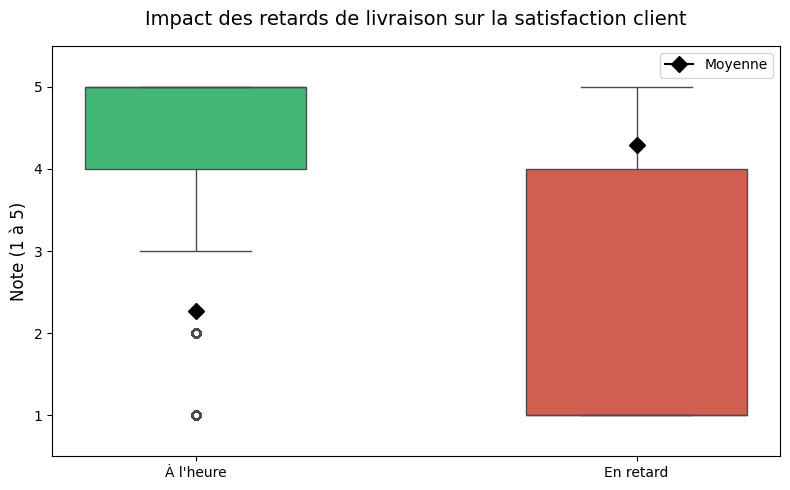

In [58]:
# Création d'un graphique clair pour le rapport
plt.figure(figsize=(8, 5))
ax = sns.boxplot(
    data=df_retard,
    x='statut',
    y='note',
    palette=['#2ecc71', '#e74c3c'],
    width=0.5
)
means = df_retard.groupby('statut')['note'].mean()
for i, mean in enumerate(means):
    ax.plot(i, mean, marker='D', color='black', markersize=8, label='Moyenne' if i == 0 else "")

plt.title("Impact des retards de livraison sur la satisfaction client", fontsize=14, pad=15)
plt.xlabel("")
plt.ylabel("Note (1 à 5)", fontsize=12)
plt.ylim(0.5, 5.5)
plt.legend()
plt.tight_layout()
plt.show()

In [59]:
df_retard.to_csv('resultats_olist.csv', index=False)